# Cognifyz Data Science Internship

## Level 2 – Data Analysis

### Objective
To analyze restaurant table booking, online delivery, price ranges, and create additional features from the existing dataset.

### Tasks Completed
1. Table Booking and Online Delivery
2. Price Range Analysis
3. Feature Engineering

Level 2 – Task 1: Table Booking and Online Delivery.

Cell 1 — Check the relevant columns

In [125]:
print(df[[
    "Has Table booking",
    "Has Online delivery",
    "Price range",
    "Aggregate rating"
]].head())

  Has Table booking Has Online delivery  Price range  Aggregate rating
0               Yes                  No            3               4.8
1               Yes                  No            3               4.5
2               Yes                  No            4               4.4
3                No                  No            4               4.9
4               Yes                  No            4               4.8


Cell 2 — Percentage of restaurants offering table booking

In [126]:
table_booking_percentage = (
    df["Has Table booking"].value_counts(normalize=True) * 100
)

print("Percentage of Restaurants with Table Booking:")
print(table_booking_percentage)

Percentage of Restaurants with Table Booking:
Has Table booking
No     87.875615
Yes    12.124385
Name: proportion, dtype: float64


Cell 3 — Visualize table booking

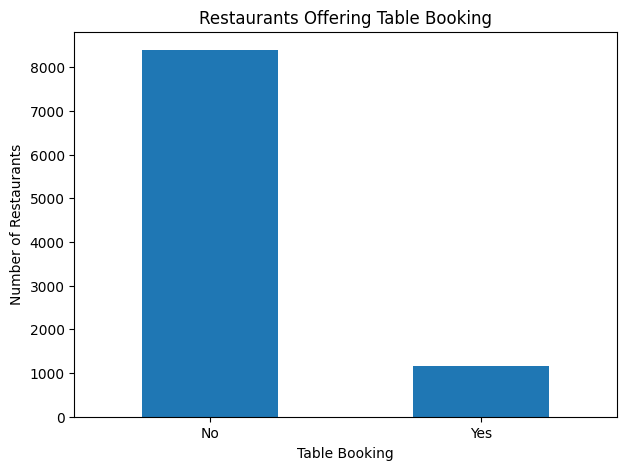

In [127]:
plt.figure(figsize=(7, 5))

df["Has Table booking"].value_counts().plot(kind="bar")

plt.xlabel("Table Booking")
plt.ylabel("Number of Restaurants")
plt.title("Restaurants Offering Table Booking")
plt.xticks(rotation=0)

plt.show()

Cell 4 — Percentage offering online delivery

In [128]:
online_delivery_percentage = (
    df["Has Online delivery"].value_counts(normalize=True) * 100
)

print("Percentage of Restaurants with Online Delivery:")
print(online_delivery_percentage)

Percentage of Restaurants with Online Delivery:
Has Online delivery
No     74.337766
Yes    25.662234
Name: proportion, dtype: float64


Cell 5 — Visualize online delivery

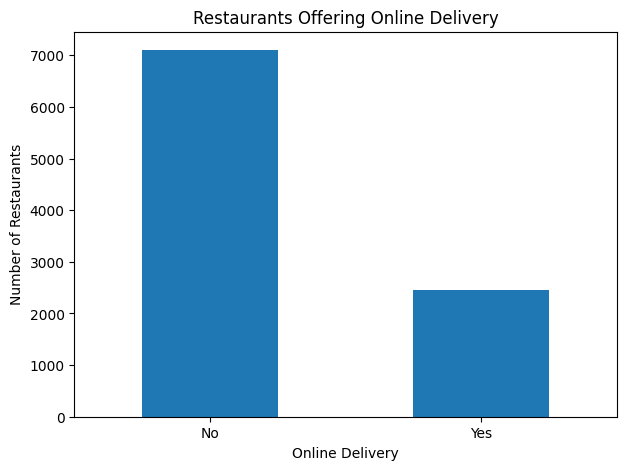

In [129]:
plt.figure(figsize=(7, 5))

df["Has Online delivery"].value_counts().plot(kind="bar")

plt.xlabel("Online Delivery")
plt.ylabel("Number of Restaurants")
plt.title("Restaurants Offering Online Delivery")
plt.xticks(rotation=0)

plt.show()

Cell 6 — Average rating with and without table booking

In [130]:
table_booking_rating = (
    df.groupby("Has Table booking")["Aggregate rating"]
    .mean()
)

print("Average Rating Based on Table Booking:")
print(table_booking_rating)

Average Rating Based on Table Booking:
Has Table booking
No     2.559359
Yes    3.441969
Name: Aggregate rating, dtype: float64


Cell 7 — Visualize the comparison

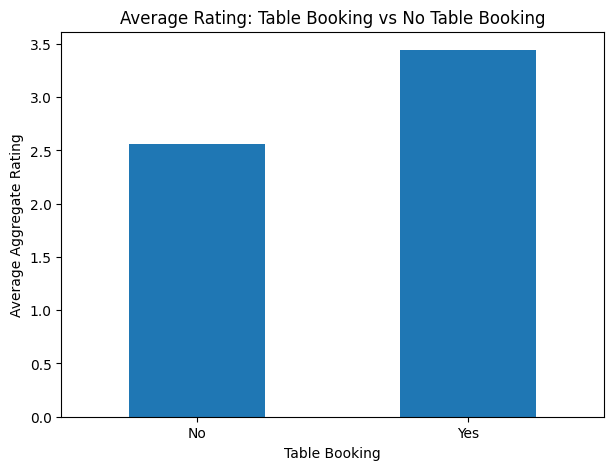

In [131]:
plt.figure(figsize=(7, 5))

table_booking_rating.plot(kind="bar")

plt.xlabel("Table Booking")
plt.ylabel("Average Aggregate Rating")
plt.title("Average Rating: Table Booking vs No Table Booking")
plt.xticks(rotation=0)

plt.show()

Cell 8 — Online delivery by price range

In [132]:
delivery_by_price = pd.crosstab(
    df["Price range"],
    df["Has Online delivery"],
    normalize="index"
) * 100

print("Online Delivery Availability by Price Range (%):")
print(delivery_by_price)

Online Delivery Availability by Price Range (%):
Has Online delivery         No        Yes
Price range                              
1                    84.225923  15.774077
2                    58.689367  41.310633
3                    70.809659  29.190341
4                    90.955631   9.044369


Cell 9 — Visualize online delivery by price range

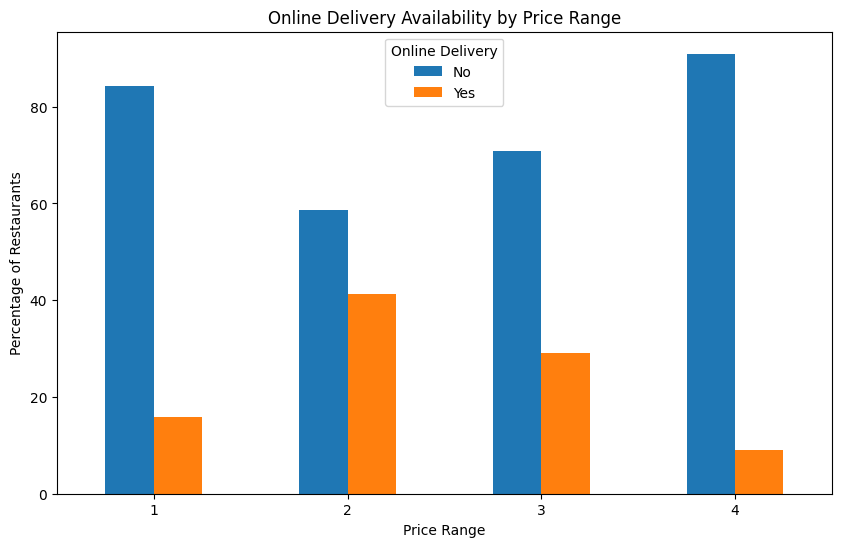

In [133]:
delivery_by_price.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Price Range")
plt.ylabel("Percentage of Restaurants")
plt.title("Online Delivery Availability by Price Range")
plt.xticks(rotation=0)

plt.legend(title="Online Delivery")

plt.show()

Cell 10 — A simple summary

In [134]:
print("===== LEVEL 2 - TASK 1 SUMMARY =====")

print("\nTable Booking:")
print(table_booking_percentage)

print("\nOnline Delivery:")
print(online_delivery_percentage)

print("\nAverage Rating by Table Booking:")
print(table_booking_rating)

print("\nOnline Delivery by Price Range:")
print(delivery_by_price)

===== LEVEL 2 - TASK 1 SUMMARY =====

Table Booking:
Has Table booking
No     87.875615
Yes    12.124385
Name: proportion, dtype: float64

Online Delivery:
Has Online delivery
No     74.337766
Yes    25.662234
Name: proportion, dtype: float64

Average Rating by Table Booking:
Has Table booking
No     2.559359
Yes    3.441969
Name: Aggregate rating, dtype: float64

Online Delivery by Price Range:
Has Online delivery         No        Yes
Price range                              
1                    84.225923  15.774077
2                    58.689367  41.310633
3                    70.809659  29.190341
4                    90.955631   9.044369


Level 2 – Task 2: Price Range Analysis.

Cell 1 — Check the price range distribution

In [135]:
print("Price Range Distribution:")
print(df["Price range"].value_counts().sort_index())

Price Range Distribution:
Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64


Cell 2 — Find the most common price range

In [136]:
most_common_price_range = df["Price range"].mode()[0]

print("Most Common Price Range:", most_common_price_range)

Most Common Price Range: 1


Cell 3 — Visualize price range distribution

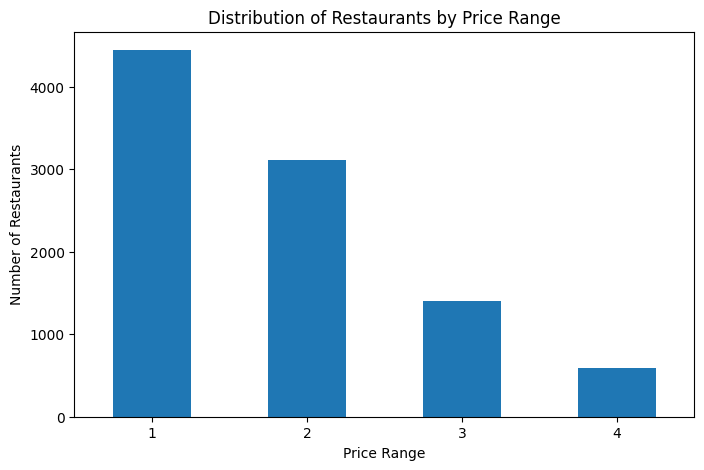

In [137]:
plt.figure(figsize=(8, 5))

df["Price range"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")
plt.title("Distribution of Restaurants by Price Range")
plt.xticks(rotation=0)

plt.show()

Cell 4 — Calculate average rating for each price range

In [138]:
average_rating_by_price = (
    df.groupby("Price range")["Aggregate rating"]
    .mean()
)

print("Average Rating for Each Price Range:")
print(average_rating_by_price)

Average Rating for Each Price Range:
Price range
1    1.999887
2    2.941054
3    3.683381
4    3.817918
Name: Aggregate rating, dtype: float64


Cell 5 — Visualize average rating

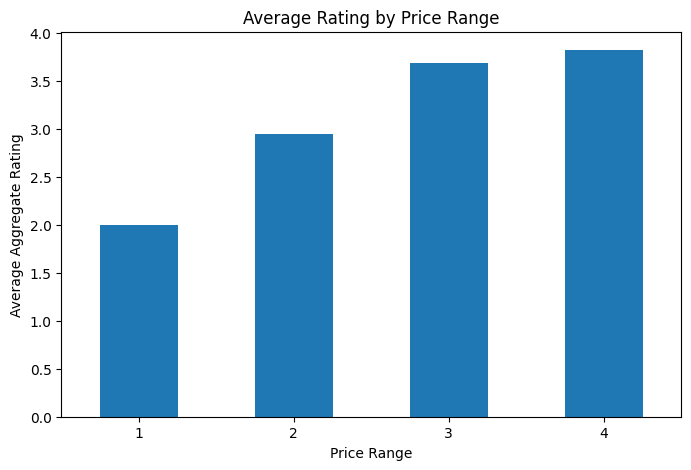

In [139]:
plt.figure(figsize=(8, 5))

average_rating_by_price.plot(kind="bar")

plt.xlabel("Price Range")
plt.ylabel("Average Aggregate Rating")
plt.title("Average Rating by Price Range")
plt.xticks(rotation=0)

plt.show()

Cell 6 — Find the price range with the highest average rating

In [140]:
highest_rating_price_range = average_rating_by_price.idxmax()
highest_average_rating = average_rating_by_price.max()

print("Price Range with Highest Average Rating:",
      highest_rating_price_range)

print("Highest Average Rating:",
      highest_average_rating)

Price Range with Highest Average Rating: 4
Highest Average Rating: 3.8179180887372017


Cell 7 — Color representing the highest average rating

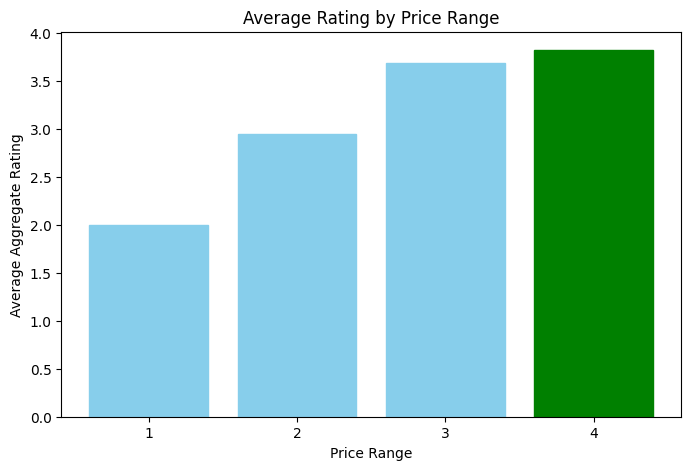

The color representing the highest average rating is: Green


In [141]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    average_rating_by_price.index.astype(str),
    average_rating_by_price.values
)

max_index = average_rating_by_price.values.argmax()

for i, bar in enumerate(bars):
    if i == max_index:
        bar.set_color("green")
    else:
        bar.set_color("skyblue")

plt.xlabel("Price Range")
plt.ylabel("Average Aggregate Rating")
plt.title("Average Rating by Price Range")

plt.show()

print(
    "The color representing the highest average rating is: Green"
)

Cell 8 — Final summary

In [142]:
print("===== LEVEL 2 - TASK 2 SUMMARY =====")

print("\nMost Common Price Range:")
print(most_common_price_range)

print("\nAverage Rating by Price Range:")
print(average_rating_by_price)

print("\nHighest Average Rating:")
print(highest_average_rating)

print("\nPrice Range with Highest Average Rating:")
print(highest_rating_price_range)

print("\nColor Representing Highest Average Rating: Green")

===== LEVEL 2 - TASK 2 SUMMARY =====

Most Common Price Range:
1

Average Rating by Price Range:
Price range
1    1.999887
2    2.941054
3    3.683381
4    3.817918
Name: Aggregate rating, dtype: float64

Highest Average Rating:
3.8179180887372017

Price Range with Highest Average Rating:
4

Color Representing Highest Average Rating: Green


Level 2 Task 3 is Feature Engineering

Cell 1 — Check the columns

In [143]:
# Check the required columns
print(df.columns.tolist())

['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


Cell 2 — Create Name and Address Length

In [144]:
# Feature Engineering: Name and Address Length

df["Restaurant Name Length"] = df["Restaurant Name"].astype(str).apply(len)
df["Address Length"] = df["Address"].astype(str).apply(len)

print(df[[
    "Restaurant Name",
    "Restaurant Name Length",
    "Address",
    "Address Length"
]].head())

          Restaurant Name  Restaurant Name Length  \
0        Le Petit Souffle                      16   
1        Izakaya Kikufuji                      16   
2  Heat - Edsa Shangri-La                      22   
3                    Ooma                       4   
4             Sambo Kojin                      11   

                                             Address  Address Length  
0  Third Floor, Century City Mall, Kalayaan Avenu...              71  
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...              67  
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...              56  
3  Third Floor, Mega Fashion Hall, SM Megamall, O...              70  
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...              64  


Cell 3 — Encode Table Booking

In [145]:
# Convert Has Table booking into numerical values

df["Has Table Booking"] = df["Has Table booking"].map({
    "Yes": 1,
    "No": 0
})

print(df["Has Table Booking"].value_counts())

Has Table Booking
0    8393
1    1158
Name: count, dtype: int64


Cell 4 — Encode Online Delivery

In [146]:
# Convert Has Online delivery into numerical values

df["Has Online Delivery"] = df["Has Online delivery"].map({
    "Yes": 1,
    "No": 0
})

print(df["Has Online Delivery"].value_counts())

Has Online Delivery
0    7100
1    2451
Name: count, dtype: int64


Cell 5 — View the engineered features

In [147]:
# Display the newly created features

features = [
    "Restaurant Name Length",
    "Address Length",
    "Has Table Booking",
    "Has Online Delivery"
]

print(df[features].head(10))

   Restaurant Name Length  Address Length  Has Table Booking  \
0                      16              71                  1   
1                      16              67                  1   
2                      22              56                  1   
3                       4              70                  0   
4                      11              64                  1   
5                      12              71                  0   
6                      10              83                  1   
7                       7              81                  1   
8                      40              69                  1   
9                       8              67                  1   

   Has Online Delivery  
0                    0  
1                    0  
2                    0  
3                    0  
4                    0  
5                    0  
6                    0  
7                    0  
8                    0  
9                    0  


Cell 6 — Check data types

In [148]:
# Check the data types of engineered features

print(df[features].dtypes)

Restaurant Name Length    int64
Address Length            int64
Has Table Booking         int64
Has Online Delivery       int64
dtype: object


Cell 7 — Simple visualization

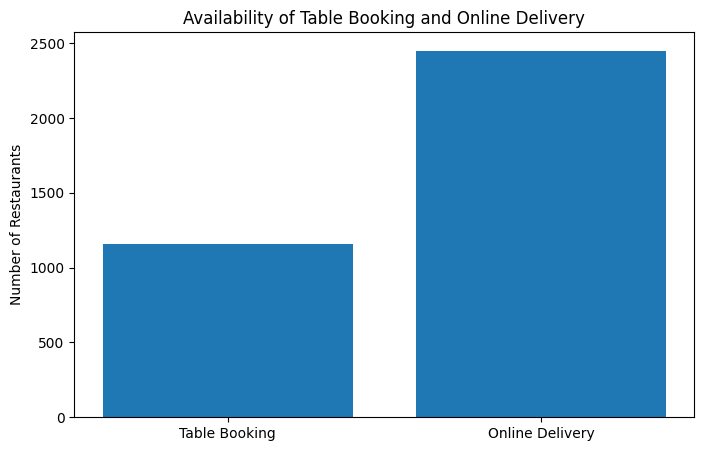

In [149]:
import matplotlib.pyplot as plt

# Count Table Booking and Online Delivery

booking_counts = df["Has Table Booking"].value_counts()
delivery_counts = df["Has Online Delivery"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Table Booking", "Online Delivery"],
    [booking_counts.get(1, 0), delivery_counts.get(1, 0)]
)

plt.title("Availability of Table Booking and Online Delivery")
plt.ylabel("Number of Restaurants")
plt.show()

Cell 8 — Final summary

In [150]:
print("FEATURE ENGINEERING SUMMARY")
print("----------------------------")
print("1. Restaurant Name Length feature created")
print("2. Address Length feature created")
print("3. Has Table Booking encoded as 1 = Yes, 0 = No")
print("4. Has Online Delivery encoded as 1 = Yes, 0 = No")
print("5. Feature engineering completed successfully")

FEATURE ENGINEERING SUMMARY
----------------------------
1. Restaurant Name Length feature created
2. Address Length feature created
3. Has Table Booking encoded as 1 = Yes, 0 = No
4. Has Online Delivery encoded as 1 = Yes, 0 = No
5. Feature engineering completed successfully


## Conclusion

The Level 2 tasks helped analyze table booking, online delivery, price ranges, and engineered features from the restaurant dataset. The analysis provided useful insights into restaurant services, ratings, pricing, and categorical feature representation.